## **Activation Functions** (corrected edition)

Changes with respect to `Activation_functions_original.ipynb`: (1) numerically safe `sigmoid`, `tanh` and `softmax` (the originals overflow for large inputs: `softmax([1000, 1001, 1002])` returned `nan`); (2) the seven near-identical plotting cells are replaced by one loop that also plots the **derivatives**, which is what backpropagation uses; (3) the SELU constants are written once and checked against the lecture; (4) the unfinished last section (data were generated and split, then nothing) now compares activation functions with `MLPClassifier` on a seeded data set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))                       # never overflows
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

def tanh(z):            return np.tanh(z)       # (e^z - e^-z)/(e^z + e^-z) gives nan for |z| > 709
def relu(z):            return np.maximum(0, z)
def leaky_relu(z, alpha=0.01):  return np.where(z > 0, z, alpha * z)
def swish(z):           return z * sigmoid(z)
def elu(z, alpha=1.0):  return np.where(z > 0, z, alpha * np.expm1(np.minimum(z, 0)))

SELU_ALPHA = 1.6732632423543772
SELU_SCALE = 1.0507009873554805
def selu(z):            return SELU_SCALE * np.where(z > 0, z, SELU_ALPHA * np.expm1(np.minimum(z, 0)))

def softmax(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max(axis=-1, keepdims=True))   # subtracting the maximum does not change the result
    return e / e.sum(axis=-1, keepdims=True)

print("tanh(800)   =", tanh(800.0), "  sigmoid(-800) =", sigmoid(-800.0))
print("softmax(1000, 1001, 1002) =", softmax(np.array([1000.0, 1001.0, 1002.0])).round(4))

tanh(800)   = 1.0   sigmoid(-800) = 0.0
softmax(1000, 1001, 1002) = [0.09   0.2447 0.6652]


### 1. The functions and their derivatives

The derivative $g'(z)$ multiplies the error signal in every layer, so its size decides whether learning is fast or the gradient vanishes.

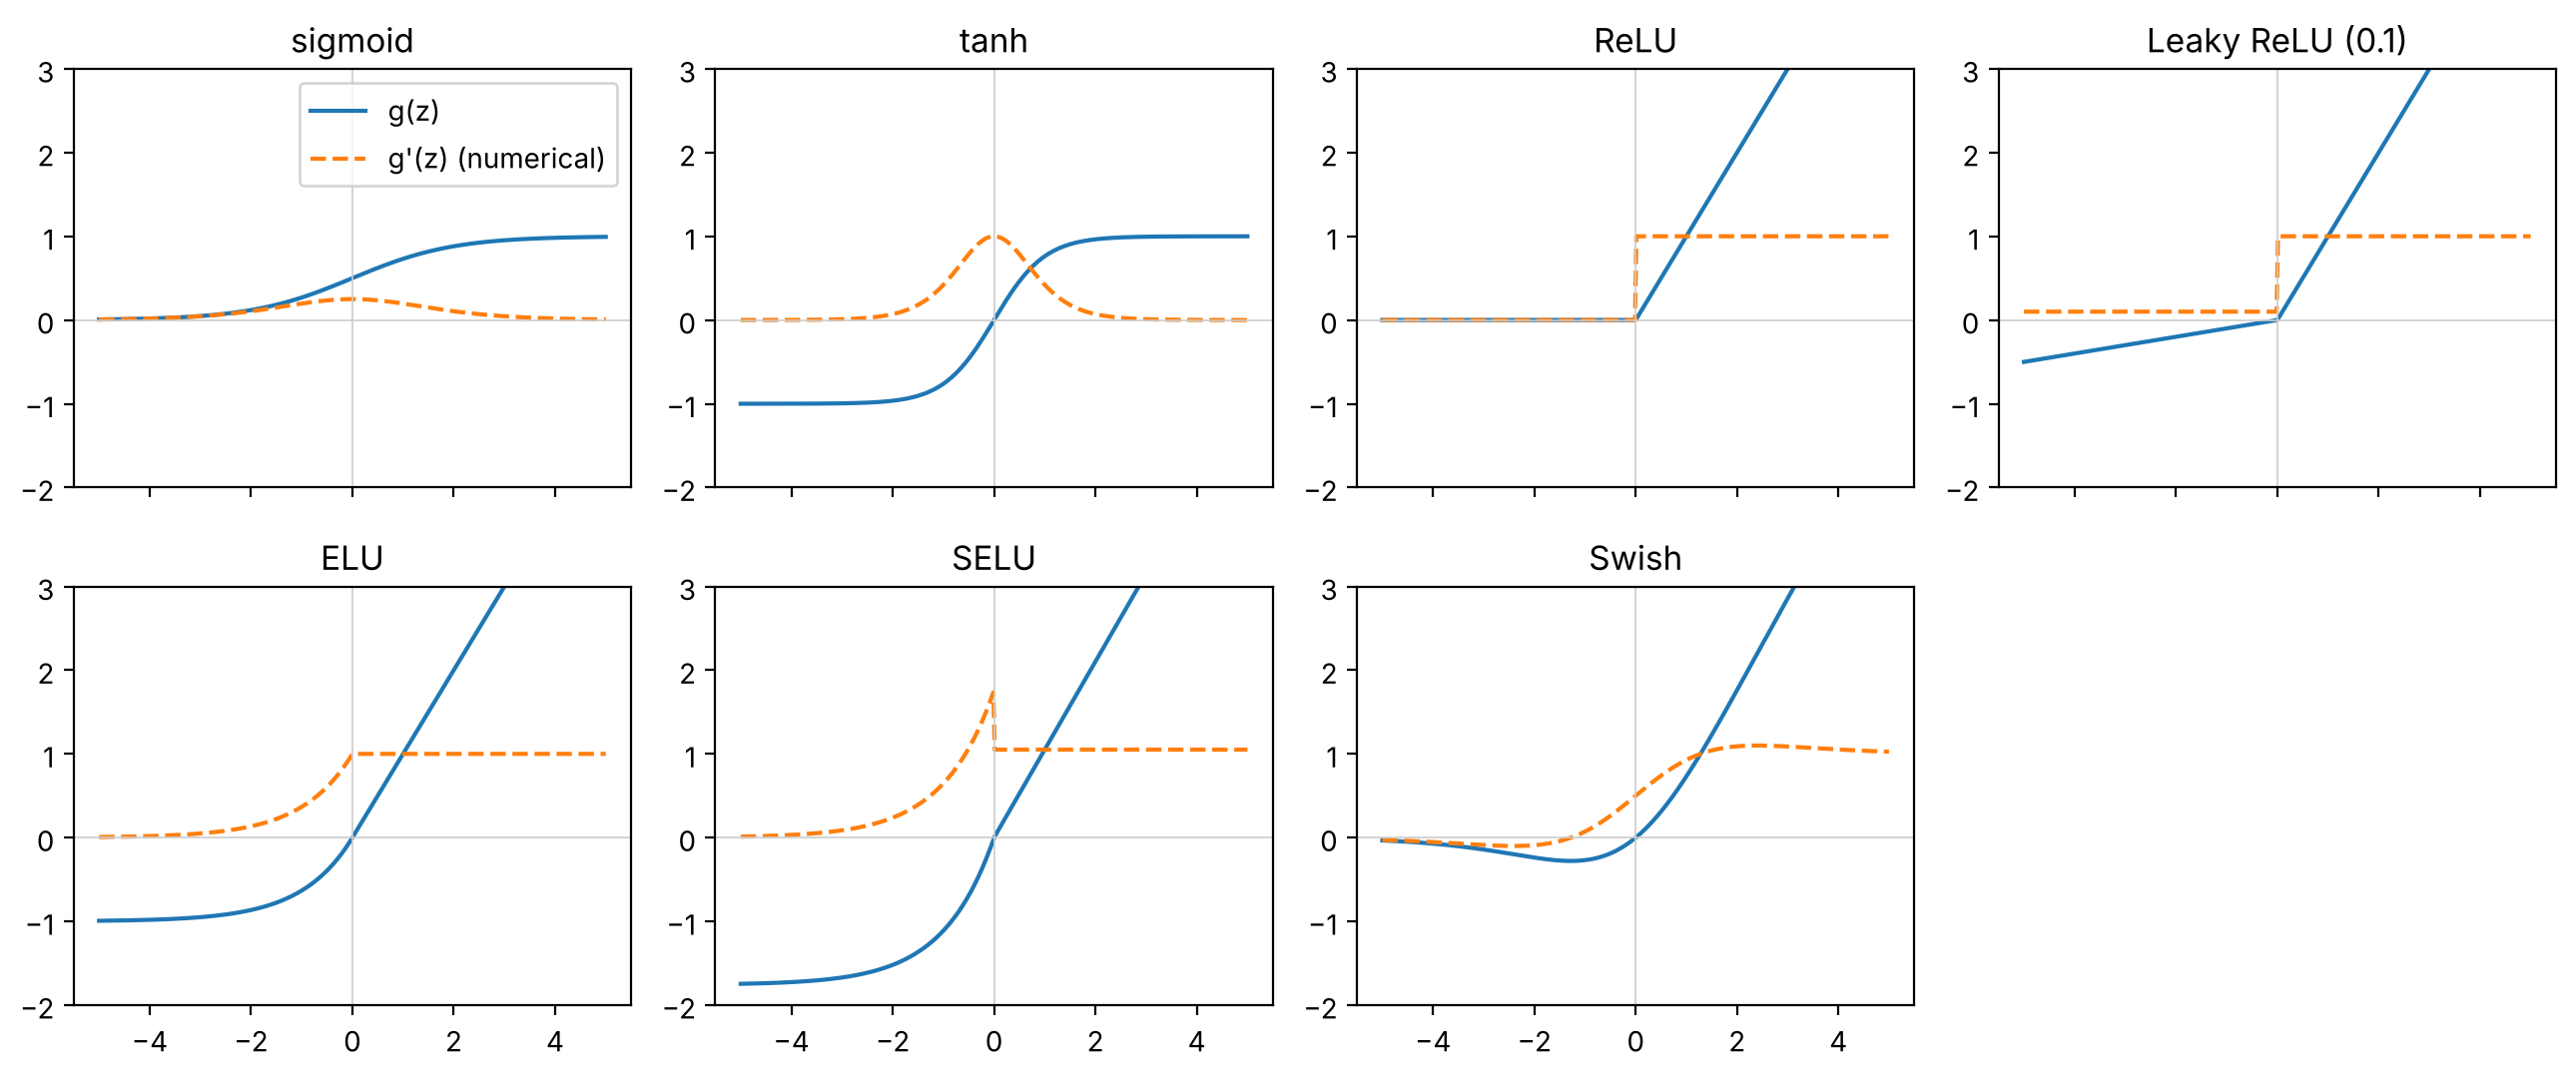

largest slope of the sigmoid (at z=0): 0.25


In [2]:
z = np.linspace(-5, 5, 400)
funcs = {"sigmoid": sigmoid, "tanh": tanh, "ReLU": relu, "Leaky ReLU (0.1)": lambda z: leaky_relu(z, 0.1),
         "ELU": elu, "SELU": selu, "Swish": swish}
h = 1e-5
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for ax, (name, f) in zip(axes.ravel(), funcs.items()):
    ax.plot(z, f(z), label="g(z)")
    ax.plot(z, (f(z + h) - f(z - h)) / (2 * h), "--", label="g'(z) (numerical)")
    ax.set_title(name); ax.axhline(0, c="0.8", lw=0.6); ax.axvline(0, c="0.8", lw=0.6); ax.set_ylim(-2, 3)
axes.ravel()[-1].axis("off"); axes[0, 0].legend()
plt.tight_layout(); plt.show()
print("largest slope of the sigmoid (at z=0):", round((sigmoid(1e-5) - sigmoid(-1e-5)) / 2e-5, 4))

### 2. Softmax

In [3]:
logits = np.array([2.0, 4.0, 1.0, 0.5])
p = softmax(logits)
print("logits       :", logits)
print("probabilities:", p.round(4), " sum =", round(p.sum(), 6))

logits       : [2.  4.  1.  0.5]
probabilities: [0.1114 0.8228 0.041  0.0248]  sum = 1.0


### 3. Does the choice of activation matter? (data, split and model are all seeded)

The original notebook stopped after the train/test split. Here a network with two hidden layers of 20 neurons is trained with each activation; `identity` has no non-linearity and is the control: a deep *linear* network is a linear model.

In [4]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings("ignore")

X, y = make_classification(n_samples=1000, n_features=20, n_informative=10, n_classes=5, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler().fit(X_train)
X_train, X_test = sc.transform(X_train), sc.transform(X_test)
print(X_train.shape, X_test.shape)

for act in ["identity", "logistic", "tanh", "relu"]:
    accs = []
    for seed in range(5):
        clf = MLPClassifier((20, 20), activation=act, max_iter=500, random_state=seed).fit(X_train, y_train)
        accs.append(clf.score(X_test, y_test))
    print(f"{act:9s} test accuracy: mean {np.mean(accs):.3f}  min {np.min(accs):.3f}  max {np.max(accs):.3f}")

(800, 20) (200, 20)


identity  test accuracy: mean 0.498  min 0.495  max 0.500


logistic  test accuracy: mean 0.581  min 0.560  max 0.600


tanh      test accuracy: mean 0.628  min 0.605  max 0.655


relu      test accuracy: mean 0.669  min 0.615  max 0.695
